In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
from sklearn.datasets import load_breast_cancer

In [4]:
X, y = load_breast_cancer(return_X_y= True)

In [5]:
from sklearn.model_selection import train_test_split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)

In [7]:
from sklearn.linear_model import LogisticRegression

In [8]:
lg = LogisticRegression(penalty= None, solver= 'sag')

In [9]:
lg.fit(X_train, y_train)

C:\Users\gpava\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,penalty,None
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'sag'
,max_iter,100
,multi_class,'deprecated'


In [22]:
y_scores = np.round(lg.predict_proba(X_test)[:, 1], 3)

In [23]:
y_scores

array([0.495, 0.   , 0.038, 0.922, 0.88 , 0.008, 0.   , 0.243, 0.865,
       0.798, 0.85 , 0.053, 0.86 , 0.674, 0.819, 0.696, 0.866, 0.896,
       0.821, 0.007, 0.437, 0.783, 0.001, 0.848, 0.895, 0.897, 0.87 ,
       0.914, 0.857, 0.   , 0.887, 0.832, 0.745, 0.512, 0.859, 0.792,
       0.093, 0.738, 0.004, 0.725, 0.85 , 0.11 , 0.872, 0.759, 0.885,
       0.757, 0.818, 0.852, 0.732, 0.862, 0.009, 0.002, 0.851, 0.873,
       0.853, 0.681, 0.837, 0.   , 0.649, 0.85 , 0.786, 0.006, 0.001,
       0.875, 0.859, 0.763, 0.011, 0.082, 0.881, 0.802, 0.473, 0.007,
       0.885, 0.776, 0.794, 0.798, 0.814, 0.416, 0.811, 0.833, 0.087,
       0.785, 0.679, 0.   , 0.149, 0.472, 0.422, 0.014, 0.935, 0.837,
       0.747, 0.665, 0.641, 0.894, 0.894, 0.813, 0.011, 0.005, 0.862,
       0.088, 0.009, 0.842, 0.001, 0.088, 0.66 , 0.726, 0.85 , 0.   ,
       0.796, 0.658, 0.029, 0.823, 0.768, 0.   ])

In [27]:
from sklearn.metrics import roc_curve, roc_auc_score, auc

In [28]:
fpr, tpr, threshold = roc_curve(y_test, y_scores)

In [29]:
threshold

array([  inf, 0.935, 0.895, 0.894, 0.887, 0.885, 0.865, 0.862, 0.86 ,
       0.859, 0.851, 0.85 , 0.842, 0.837, 0.802, 0.798, 0.783, 0.776,
       0.725, 0.696, 0.681, 0.674, 0.658, 0.649, 0.495, 0.093, 0.088,
       0.014, 0.009, 0.008, 0.007, 0.002, 0.001, 0.   ])

In [30]:
roc_auc = auc(fpr, tpr)

In [31]:
roc_auc

0.9872256796593515

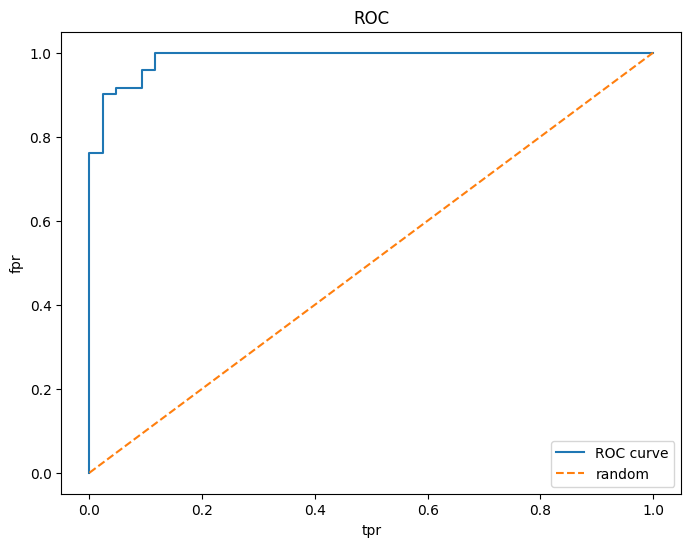

In [34]:
plt.figure(figsize= (8, 6))
plt.plot(fpr, tpr, label = 'ROC curve')
plt.plot([0, 1], [0, 1], linestyle = '--', label = 'random')
plt.xlabel('tpr')
plt.ylabel('fpr')
plt.title('ROC')
plt.legend()
plt.show()

In [35]:
roc_auc_score(y_test, y_scores)

0.9872256796593515

In [40]:
j = tpr-fpr

In [42]:
optimal = np.argmax(j)
optimal_threshold = threshold[optimal]
optimal_threshold

np.float64(0.495)